# Dataset 3 — EDA and Preliminary Feature Screening

**Project:** Daily Lifestyle Habits and Student Stress Prediction  
**Scope:** Pandas, cleaning checks, visualizations and provisional feature selection. No ML training.

**Target:** Question 14 — self-reported academic workload stress. Class imbalance needs attention when interpreting percentages.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")

## 1. Read CSV and rename long question columns to Q1…Q15

In [2]:
df3_raw = pd.read_csv("../data/raw/dataset3.csv")
print("Original dimensions:", df3_raw.shape)
question_names = {col: "Q"+col.split(".", 1)[0].strip()
                  for col in df3_raw.columns if col and col[0].isdigit() and "." in col}
df3 = df3_raw.rename(columns=question_names).copy()
for original, short in question_names.items():
    print(f"{short}: {original}")
display(df3.head())
df3.info()

Original dimensions: (996, 16)
Q1: 1. What is your year of study?
Q2: 2. What is your gender?
Q3: 3. How often do you have difficulty falling asleep at night? 
Q4: 4. On average, how many hours of sleep do you get on a typical day?
Q5: 5. How often do you wake up during the night and have trouble falling back asleep?
Q6: 6. How would you rate the overall quality of your sleep?
Q7: 7. How often do you experience difficulty concentrating during lectures or studying due to lack of sleep?
Q8: 8. How often do you feel fatigued during the day, affecting your ability to study or attend classes?
Q9: 9. How often do you miss or skip classes due to sleep-related issues (e.g., insomnia, feeling tired)?
Q10: 10. How would you describe the impact of insufficient sleep on your ability to complete assignments and meet deadlines?
Q11: 11. How often do you use electronic devices (e.g., phone, computer) before going to sleep?
Q12: 12. How often do you consume caffeine (coffee, energy drinks) to stay awa

,Timestamp,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,Q11,Q12,Q13,Q14,Q15
0,10/24/2024 16:51:15,Graduate student,Male,Often (5-6 times a week),7-8 hours,Often (5-6 times a week),Good,Sometimes,Often,Often (3-4 times a week),Moderate impact,Often (5-6 times a week),Rarely (1-2 times a week),Sometimes (3-4 times a week),High stress,Average
1,10/24/2024 16:51:51,Third year,Male,Often (5-6 times a week),7-8 hours,Often (5-6 times a week),Good,Often,Sometimes,Sometimes (1-2 times a week),Major impact,Sometimes (3-4 times a week),Sometimes (3-4 times a week),Sometimes (3-4 times a week),Low stress,Good
2,10/24/2024 16:52:21,First year,Female,Sometimes (3-4 times a week),7-8 hours,Sometimes (3-4 times a week),Good,Often,Often,Sometimes (1-2 times a week),Major impact,Often (5-6 times a week),Often (5-6 times a week),Often (5-6 times a week),High stress,Below Average
3,10/24/2024 16:53:00,Third year,Male,Often (5-6 times a week),More than 8 hours,Sometimes (3-4 times a week),Poor,Often,Often,Rarely (1-2 times a month),Minor impact,Sometimes (3-4 times a week),Sometimes (3-4 times a week),Every day,Extremely high stress,Excellent
4,10/24/2024 16:53:25,Graduate student,Male,Often (5-6 times a week),7-8 hours,Often (5-6 times a week),Very good,Always,Sometimes,Sometimes (1-2 times a week),Moderate impact,Sometimes (3-4 times a week),Sometimes (3-4 times a week),Often (5-6 times a week),Low stress,Average


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 996 entries, 0 to 995
Data columns (total 16 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Timestamp  996 non-null    object
 1   Q1         996 non-null    object
 2   Q2         996 non-null    object
 3   Q3         996 non-null    object
 4   Q4         996 non-null    object
 5   Q5         996 non-null    object
 6   Q6         996 non-null    object
 7   Q7         996 non-null    object
 8   Q8         996 non-null    object
 9   Q9         996 non-null    object
 10  Q10        996 non-null    object
 11  Q11        996 non-null    object
 12  Q12        996 non-null    object
 13  Q13        996 non-null    object
 14  Q14        996 non-null    object
 15  Q15        996 non-null    object
dtypes: object(16)
memory usage: 124.6+ KB


## 2. Data quality

In [3]:
print("Missing values:")
display(df3.isna().sum().to_frame("missing"))
print("Exact duplicate rows:",df3.duplicated().sum())
print("Class labels and counts:")
display(df3["Q14"].value_counts(dropna=False))

Missing values:


,missing
Timestamp,0
Q1,0
Q2,0
Q3,0
Q4,0
Q5,0
Q6,0
Q7,0
Q8,0
Q9,0


Exact duplicate rows: 0
Class labels and counts:


Q14
Extremely high stress    490
High stress              432
Low stress                63
No stress                 11
Name: count, dtype: int64

## 3. Plot the stress-target distribution

Recorded category labels: ['High stress', 'Low stress', 'Extremely high stress', 'No stress']


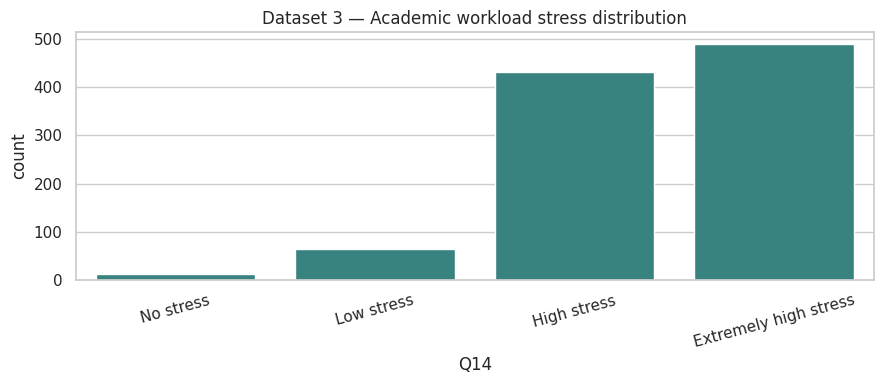

High/Extremely high percentage: 92.6


In [4]:
target_d3 = "Q14"
print("Recorded category labels:", list(df3[target_d3].unique()))
# Order only categories that actually exist. This avoids creating fake zero-count categories.
preferred = ["No stress", "Low stress", "High stress", "Extremely high stress"]
order = [c for c in preferred if c in set(df3[target_d3])]
order += [c for c in df3[target_d3].dropna().unique() if c not in order]
plt.figure(figsize=(9,4))
sns.countplot(data=df3,x=target_d3,order=order,color="#2c8f8b")
plt.title("Dataset 3 — Academic workload stress distribution")
plt.xticks(rotation=15);plt.tight_layout();plt.show()
print("High/Extremely high percentage:", round(100*df3[target_d3].isin(["High stress","Extremely high stress"]).mean(),1))

## 4. Examine every survey factor vs Q14

Row-normalized heatmaps compare stress distributions for each answer category. **Always check counts**, especially given the small Low/No stress classes. Q1–Q13 and Q15 are explored; timestamp and Q14 are excluded.

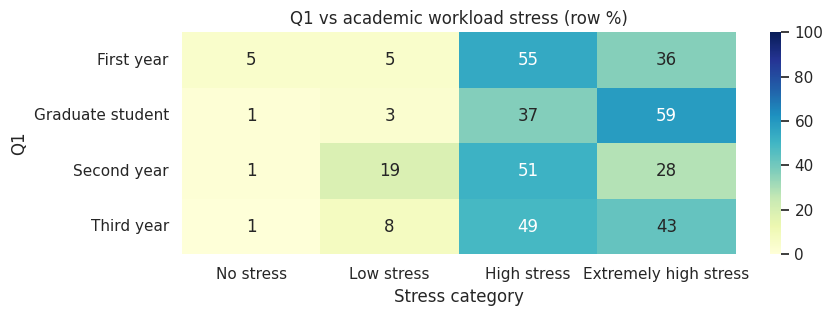

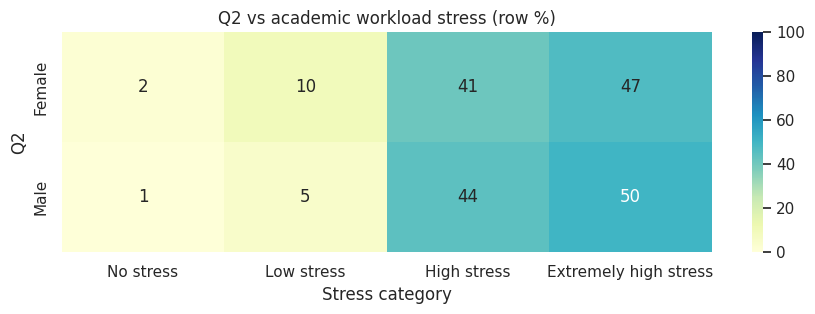

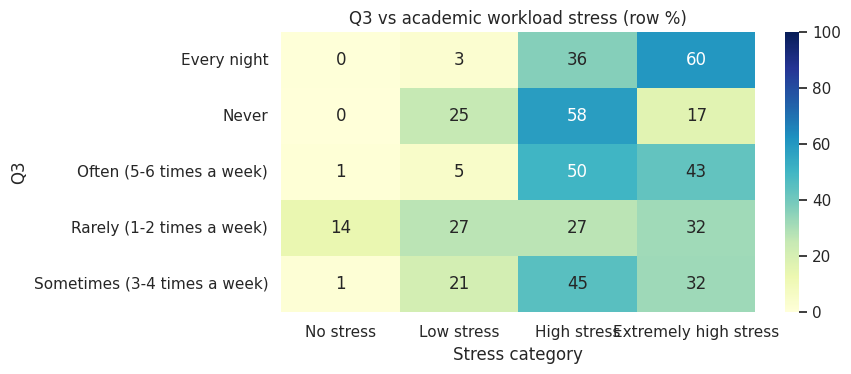

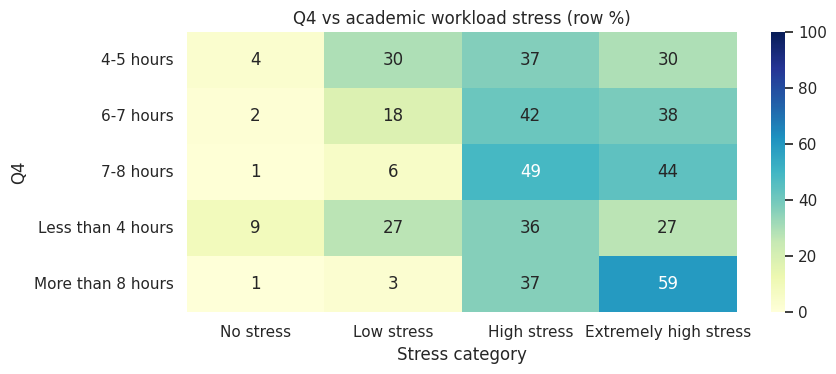

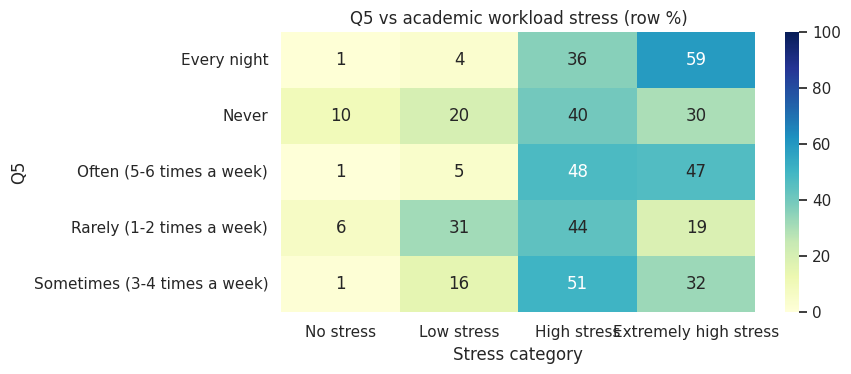

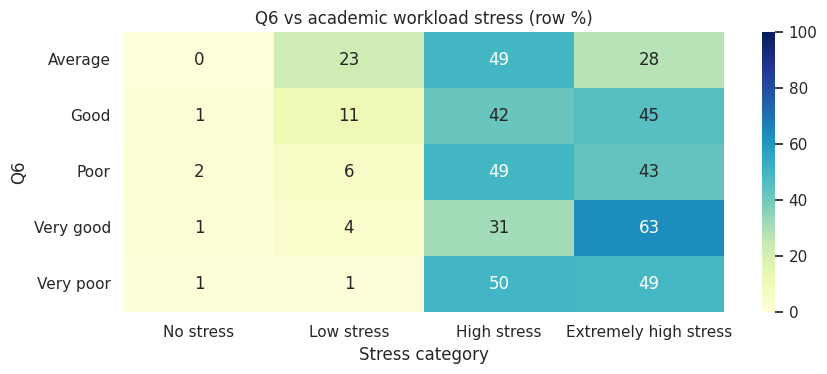

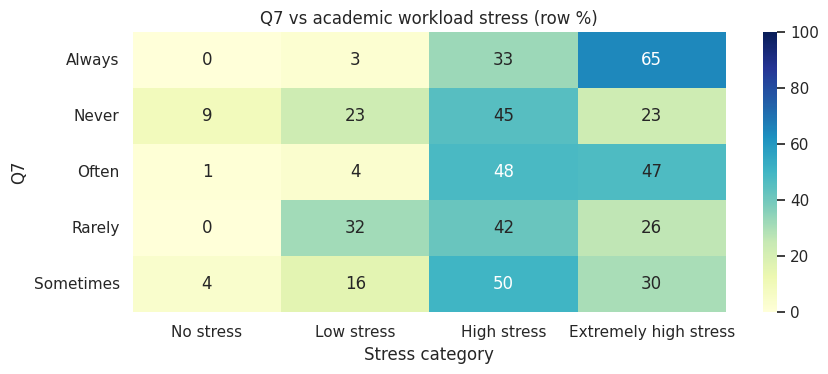

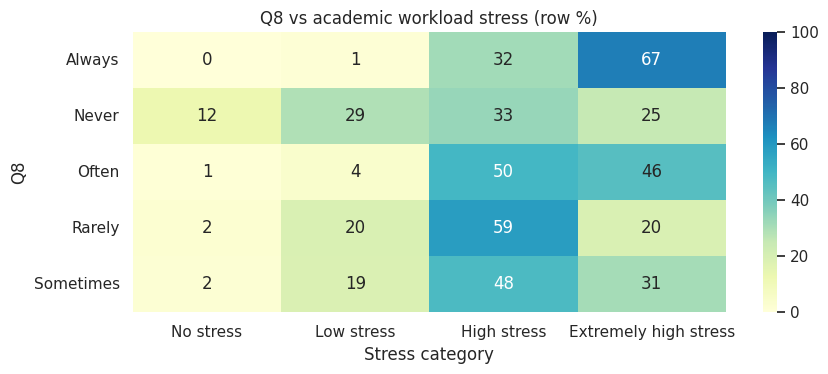

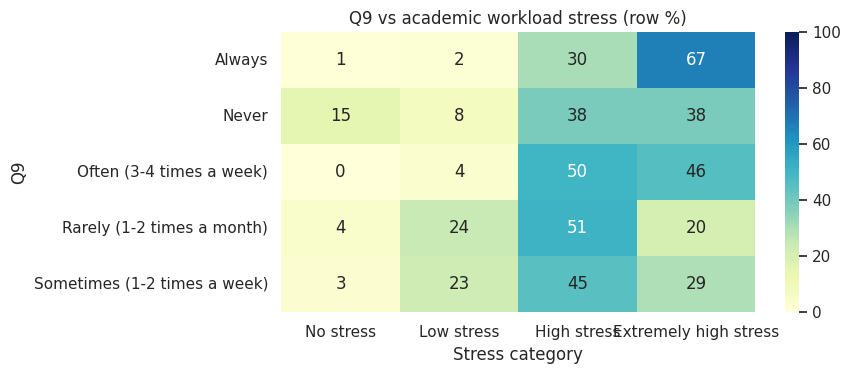

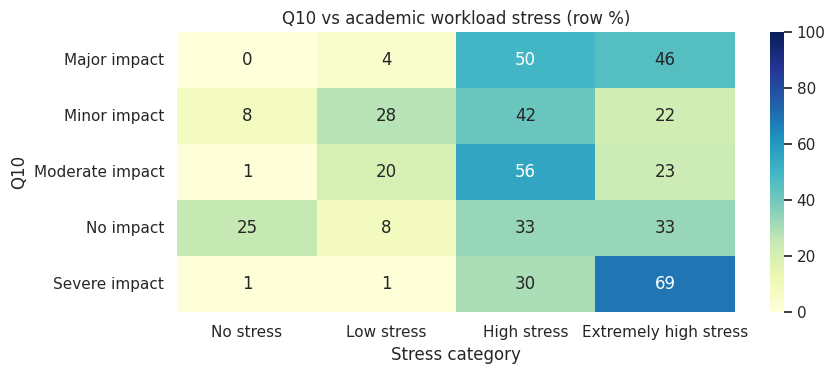

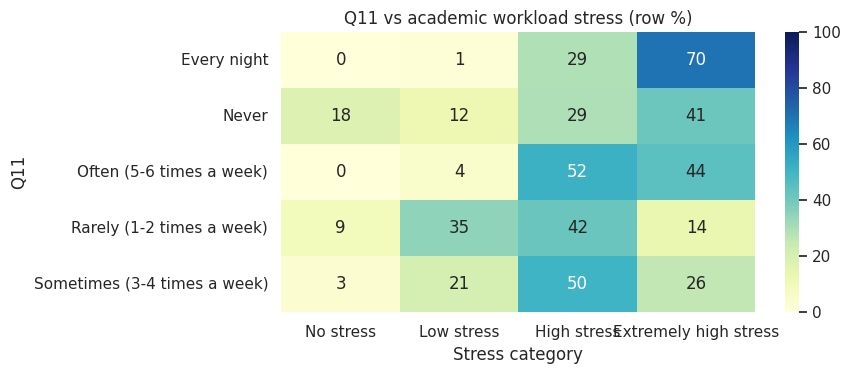

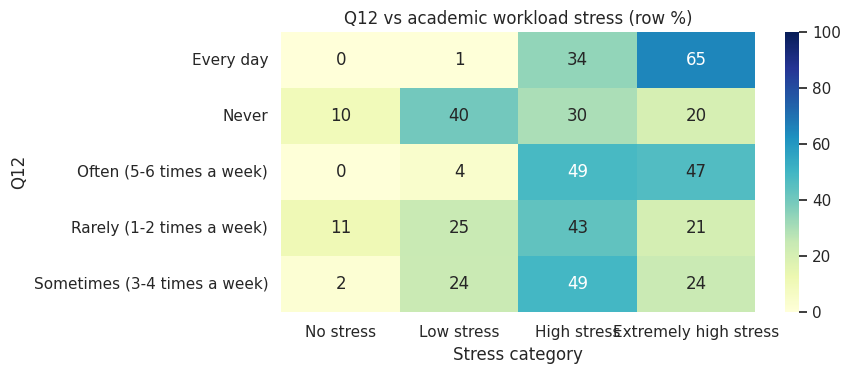

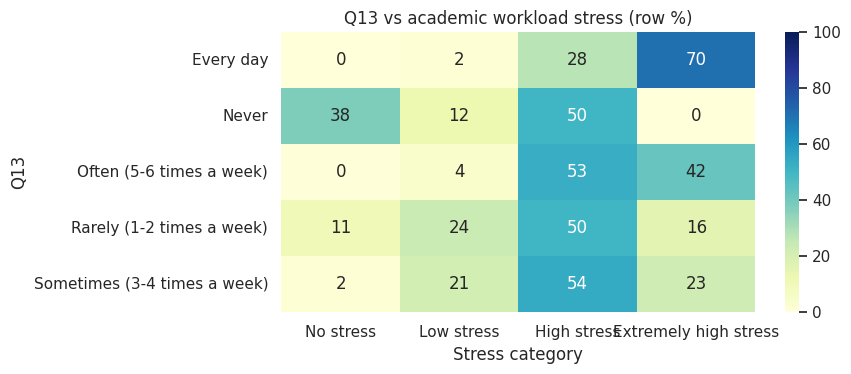

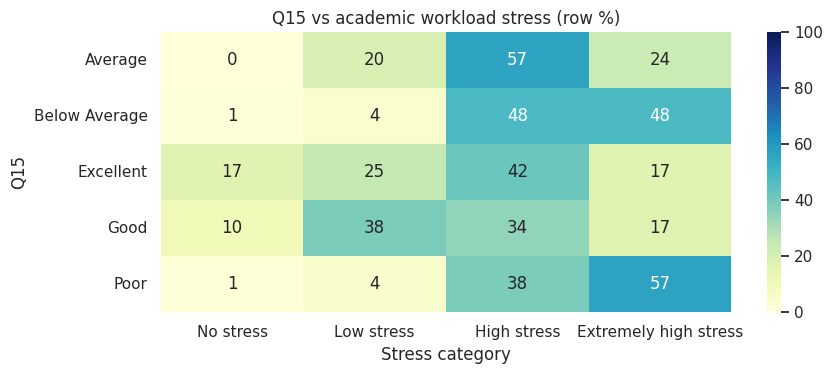

In [5]:
candidate_factors_d3 = [f"Q{i}" for i in list(range(1,14))+[15]]
for factor in candidate_factors_d3:
    counts = pd.crosstab(df3[factor],df3[target_d3])
    if counts.empty: continue
    pct = counts.div(counts.sum(axis=1),axis=0).mul(100).reindex(columns=order,fill_value=0)
    plt.figure(figsize=(9,max(3.3,0.58*len(pct)+1)))
    sns.heatmap(pct,annot=True,fmt=".0f",cmap="YlGnBu",vmin=0,vmax=100)
    plt.title(f"{factor} vs academic workload stress (row %)")
    plt.xlabel("Stress category");plt.ylabel(factor)
    plt.tight_layout();plt.show()

## 5. Review candidate features and identify a shortlist

In [6]:
core_qs = ["Q3","Q4","Q5","Q6","Q8","Q11","Q12","Q13"]
extra_qs = ["Q7","Q9","Q10","Q15"]
review3 = pd.DataFrame({
    "Question":candidate_factors_d3,
    "Description":[question_names and next((orig for orig,s in question_names.items() if s==q),q) for q in candidate_factors_d3],
    "Decision":["Shortlist" if q in core_qs else "Explore further" if q in extra_qs else "Lower priority" for q in candidate_factors_d3],
    "Reason":["Sleep/lifestyle input" if q in core_qs else "Potential consequence/outcome, examine with care" if q in extra_qs else "Demographic rather than daily habit" for q in candidate_factors_d3]
})
display(review3)
print("Target Q14 and Timestamp are excluded from input candidates.")

,Question,Description,Decision,Reason
0,Q1,1. What is your year of study?,Lower priority,Demographic rather than daily habit
1,Q2,2. What is your gender?,Lower priority,Demographic rather than daily habit
2,Q3,3. How often do you have difficulty falling as...,Shortlist,Sleep/lifestyle input
3,Q4,"4. On average, how many hours of sleep do you ...",Shortlist,Sleep/lifestyle input
4,Q5,5. How often do you wake up during the night a...,Shortlist,Sleep/lifestyle input
5,Q6,6. How would you rate the overall quality of y...,Shortlist,Sleep/lifestyle input
6,Q7,7. How often do you experience difficulty conc...,Explore further,"Potential consequence/outcome, examine with care"
7,Q8,8. How often do you feel fatigued during the d...,Shortlist,Sleep/lifestyle input
8,Q9,9. How often do you miss or skip classes due t...,Explore further,"Potential consequence/outcome, examine with care"
9,Q10,10. How would you describe the impact of insuf...,Explore further,"Potential consequence/outcome, examine with care"


Target Q14 and Timestamp are excluded from input candidates.


## 6. Create selected DataFrame and focused plots

,Q3,Q4,Q5,Q6,Q8,Q11,Q12,Q13,Q14
0,Often (5-6 times a week),7-8 hours,Often (5-6 times a week),Good,Often,Often (5-6 times a week),Rarely (1-2 times a week),Sometimes (3-4 times a week),High stress
1,Often (5-6 times a week),7-8 hours,Often (5-6 times a week),Good,Sometimes,Sometimes (3-4 times a week),Sometimes (3-4 times a week),Sometimes (3-4 times a week),Low stress
2,Sometimes (3-4 times a week),7-8 hours,Sometimes (3-4 times a week),Good,Often,Often (5-6 times a week),Often (5-6 times a week),Often (5-6 times a week),High stress
3,Often (5-6 times a week),More than 8 hours,Sometimes (3-4 times a week),Poor,Often,Sometimes (3-4 times a week),Sometimes (3-4 times a week),Every day,Extremely high stress
4,Often (5-6 times a week),7-8 hours,Often (5-6 times a week),Very good,Sometimes,Sometimes (3-4 times a week),Sometimes (3-4 times a week),Often (5-6 times a week),Low stress


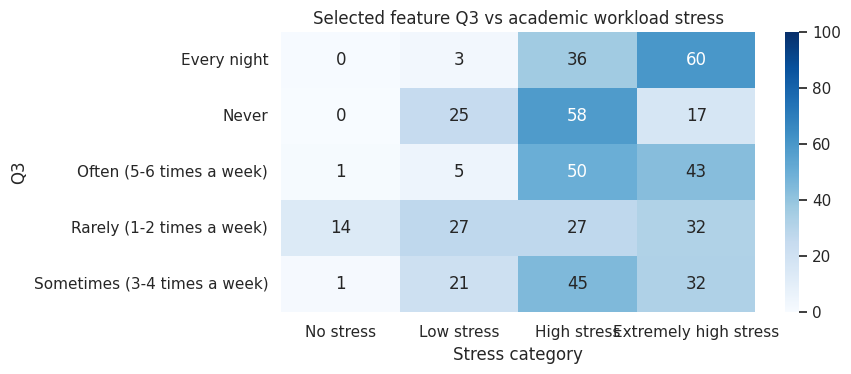

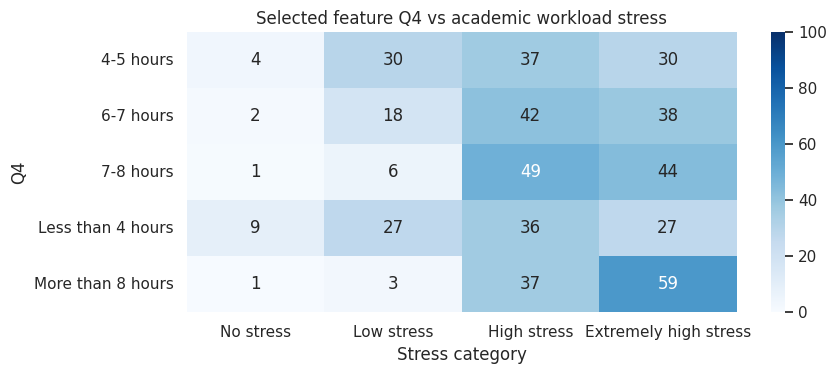

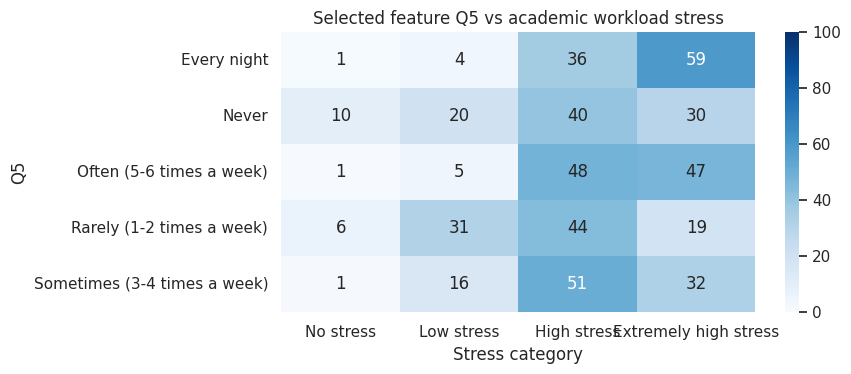

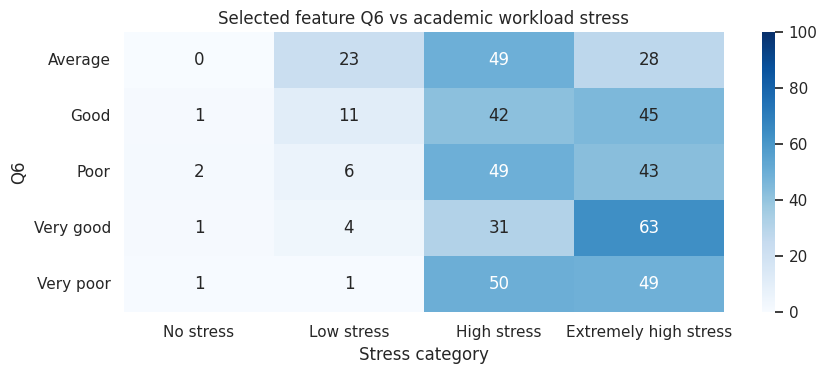

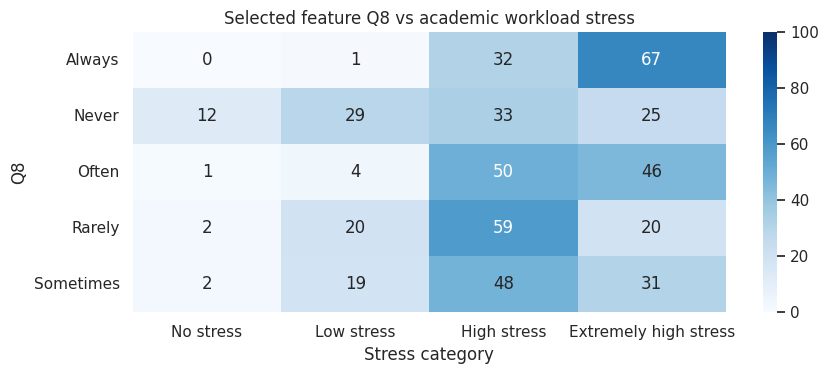

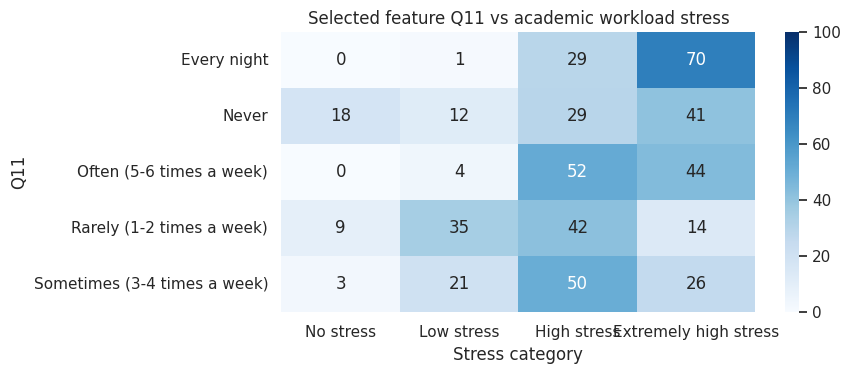

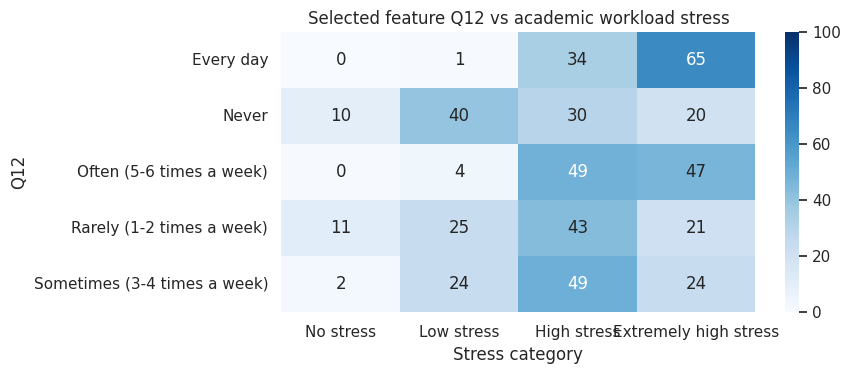

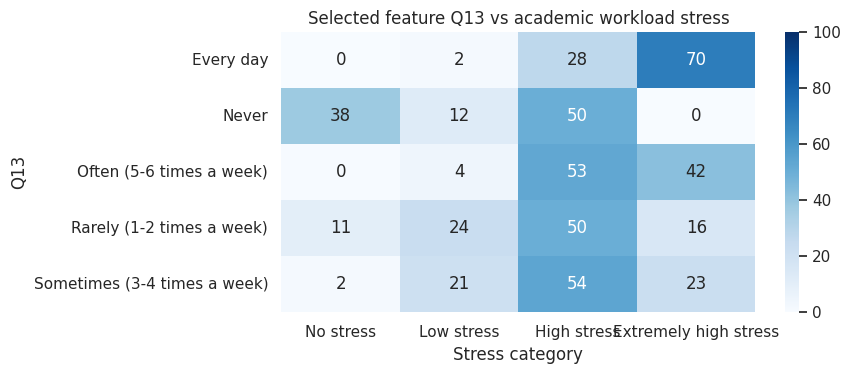

In [7]:
selected_features_d3 = core_qs.copy()
selected_df_d3 = df3[selected_features_d3+[target_d3]].copy()
display(selected_df_d3.head())
for factor in selected_features_d3:
    counts = pd.crosstab(df3[factor],df3[target_d3])
    percentages = counts.div(counts.sum(axis=1),axis=0).mul(100).reindex(columns=order,fill_value=0)
    plt.figure(figsize=(9,max(3.3,0.58*len(percentages)+1)))
    sns.heatmap(percentages,annot=True,fmt=".0f",cmap="Blues",vmin=0,vmax=100)
    plt.title(f"Selected feature {factor} vs academic workload stress")
    plt.xlabel("Stress category");plt.ylabel(factor)
    plt.tight_layout();plt.show()

## 7. Findings and limitations

- **996 records and 16 original columns** (Timestamp plus Q1–Q15).
- Q14 directly asks about academic-workload stress, not general stress.
- The target is **heavily imbalanced**: the vast majority report High or Extremely High stress. A high overall accuracy could hide errors for the rare Low/No classes.
- Q3, Q4, Q5, Q6, Q8, Q11, Q12 and Q13 are a **provisional lifestyle shortlist**. Their visual patterns are descriptive, not proven causes or validated predictive features.
- The original data are unchanged. Additional fields may be reconsidered during model evaluation.